In [58]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

In [59]:
SEED = 42

In [60]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.model_selection import train_test_split

df = pd.read_parquet("../data-nutriscope/nutriscope_ml_sample.parquet")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30041 entries, 0 to 30040
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   code                            30041 non-null  str    
 1   product_name                    29655 non-null  str    
 2   brands                          23770 non-null  str    
 3   pnns_groups_1                   30041 non-null  str    
 4   pnns_groups_2                   30041 non-null  str    
 5   nova_group                      16938 non-null  Int64  
 6   additives_n                     17653 non-null  Int64  
 7   energy-kcal_100g                30041 non-null  float64
 8   fat_100g                        30041 non-null  float64
 9   saturated-fat_100g              30041 non-null  float64
 10  carbohydrates_100g              30041 non-null  float64
 11  sugars_100g                     30041 non-null  float64
 12  fiber_100g                      15976 non-n

In [61]:
def split_train_test(X, y, split):
    train = (split == "train")
    test = (split == "test")

    return X.iloc[train], X.iloc[test], y.iloc[train], y.iloc[test]

In [62]:
y = df["nutriscore_grade"]
X = df.drop(columns=[
    y.name, "nutriscore_score", "code", "product_name", "brands", "completeness", "last_modified", "split"
])

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = split_train_test(X, y, df["split"])
X_train.shape, X_test.shape

((24076, 13), (5965, 13))

## Baseline

In [63]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate


baselines = {}
average = "macro"
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for strategy in ["most_frequent", "stratified"]:
    classifier = DummyClassifier(strategy=strategy, random_state=SEED)
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", classifier),
    ])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    baselines[repr(classifier)] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0, average=average),
        "recall" : recall_score(y_test, pred, average=average),
        "f1": f1_score(y_test, pred, average=average),
        "cv": cross_validate(pipeline, X, y, cv=cv, scoring="f1_macro")["test_score"].mean()
    }


for max_depth in [3, 8]:
    classifier = DecisionTreeClassifier(max_depth=max_depth, random_state=SEED)
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", classifier),
    ])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    baselines[repr(classifier)] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0, average=average),
        "recall" : recall_score(y_test, pred, average=average),
        "f1": f1_score(y_test, pred, average=average),
        "cv": cross_validate(pipeline, X, y, cv=cv, scoring="f1_macro")["test_score"].mean()
    }

pd.DataFrame(baselines).T.round(3).sort_values("accuracy", ascending=False)

,accuracy,precision,recall,f1,cv
"DecisionTreeClassifier(max_depth=8, random_state=42)",0.775,0.749,0.744,0.746,0.742
"DecisionTreeClassifier(max_depth=3, random_state=42)",0.527,0.368,0.420,0.364,0.361
"DummyClassifier(random_state=42, strategy='most_frequent')",0.288,0.058,0.200,0.090,0.089
"DummyClassifier(random_state=42, strategy='stratified')",0.217,0.192,0.192,0.192,0.203


In [64]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# SimpleImputer(add_indicator=True) donnera l'attribute missing_indicator sur la sortie du preprocessing

optional_features = ["fruits-vegetables-legumes_100g", "fiber_100g"]
numeric_features = list(set(num_cols) - set(optional_features))

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("opt", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]), optional_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.2), cat_cols),
])

def add_features(X):
    return X

filepaths = []
models_path = Path("models")
models_path.mkdir(exist_ok=True)
for classifier in [
    LogisticRegression(class_weight="balanced", random_state=SEED),
    RandomForestClassifier(random_state=SEED)
]:

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ('feature_engineering', FunctionTransformer(add_features)),
        ("model", classifier),
    ])

    pipeline.fit(X_train, y_train)
    filepath = models_path / f"{classifier.__class__.__name__}.pkl"
    filepaths.append(filepath)
    joblib.dump(pipeline, filepath)
    print(filepath.absolute())


c:\Users\Administrateur\Documents\Cours\NutriScope - Projet\Nutriscope_team_delegue\notebooks\models\LogisticRegression.pkl
c:\Users\Administrateur\Documents\Cours\NutriScope - Projet\Nutriscope_team_delegue\notebooks\models\RandomForestClassifier.pkl


In [65]:
scores = {}
pipelines = {}

for filepath in filepaths:
    pipeline = joblib.load(filepath)
    pipelines[filepath.stem] = pipeline

    scores[filepath.stem] = cross_validate(pipeline, X, y, cv=cv, scoring=["f1_macro", "accuracy"], n_jobs=-1)

comparing = pd.DataFrame([
    {
        "modele" : name,
        "f1_moy" : score['test_f1_macro'].mean(),
        "f1_std" : score['test_f1_macro'].std(),
        "accuracy_moy" : score['test_accuracy'].mean(),
        "accuracy_std" : score['test_accuracy'].std(),
        "temps_fit_moy" : score['fit_time'].mean()
    }
    for name, score in scores.items()
])
comparing

,modele,f1_moy,f1_std,accuracy_moy,accuracy_std,temps_fit_moy
0,LogisticRegression,0.673714,0.002697,0.691555,0.003058,0.595774
1,RandomForestClassifier,0.864479,0.002202,0.883526,0.002303,2.531618


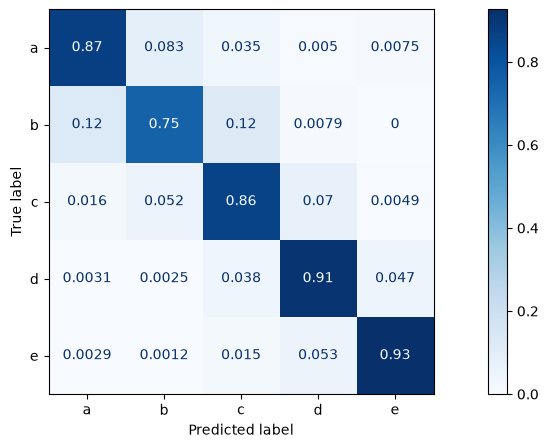

In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = pipelines["RandomForestClassifier"].predict(X_test)
grades = list("abcde")
cm = confusion_matrix(y_test, y_pred, labels=grades, normalize="true")


fig, axes = plt.subplots(1,1, figsize=(14,5))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=grades)
display.plot(ax=axes, cmap="Blues")
plt.show()

In [67]:
distribution = y.value_counts(normalize=True).sort_index()
ratio = distribution.max() / distribution.min()
print(distribution.round(2))
print(f"Ratio classe majoritaire / classe minoritaire : {ratio:.1f}")

nutriscore_grade
a    0.13
b    0.11
c    0.21
d    0.26
e    0.29
Name: proportion, dtype: float64
Ratio classe majoritaire / classe minoritaire : 2.7


In [68]:
# SMOTE + model brut et class_weight="balanced"
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

smote_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=SEED)),
    ("model", RandomForestClassifier(random_state=SEED)),
])

scores_smote = cross_validate(smote_pipeline, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
# resultats["Random Forest + SMOTE"] = scores_smote["test_score"]
# print(f"{'Random Forest + SMOTE':28s} f1_macro = {scores_smote['test_score'].mean():.3f} (+/- {scores_smote['test_score'].std():.3f})")

# comparatif = pd.DataFrame({
#     "f1_macro_moy": {nom: s.mean() for nom, s in resultats.items()},
#     "f1_macro_std": {nom: s.std() for nom, s in resultats.items()},
# })
# comparatif.sort_values("f1_macro_moy", ascending=False)


In [69]:
X_pred = X_test.copy()
X_pred[y.name] = y_test
X_pred[f"{y.name}_pred"] = y_pred
X_pred.head()

,pnns_groups_1,pnns_groups_2,nova_group,additives_n,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-legumes_100g,nutriscore_grade,nutriscore_grade_pred
1,Fruits and vegetables,Soups,4,0,28.0,0.5,0.3,4.7,2.4,1.0,0.7,0.67,72.977007,b,b
4,Composite foods,One-dish meals,3,0,54.0,0.3,0.0,6.8,0.0,4.0,4.0,0.08,100.000000,a,a
7,Sugary snacks,Sweets,3,0,573.5,40.5,7.8,40.7,37.3,7.8,7.6,0.05,0.000000,e,e
10,Cereals and potatoes,Breakfast cereals,<NA>,<NA>,371.0,7.1,1.6,60.0,1.0,NaN,12.0,0.01,NaN,b,a
14,Composite foods,Sandwiches,<NA>,<NA>,164.0,5.2,1.3,24.0,1.9,3.2,5.8,0.60,NaN,b,c


## Boosting

In [75]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

boosters = {
    "XGBoost" : XGBClassifier(random_state=SEED),
    "LightGbm" : LGBMClassifier(random_state=SEED, verbosity=-1),
    "CatBoost": CatBoostClassifier(random_state=SEED, allow_writing_files=False),
    "HistGradient": HistGradientBoostingClassifier(random_state=SEED)
}

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)  # fit induit l'apprentissage. À ne pas faire sur les données de test
y_test_encoded = label_encoder.transform(y_test)

for nom, model in boosters.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train_encoded)
    acc = accuracy_score(y_test_encoded, pipeline.predict(X_test))
    print(f"accuracy {nom} : {acc}")

accuracy XGBoost : 0.8910310142497905
accuracy LightGbm : 0.8913663034367142
Learning rate set to 0.093064
0:	learn: 1.4943493	total: 7.18ms	remaining: 7.18s
1:	learn: 1.4021471	total: 13.6ms	remaining: 6.78s
2:	learn: 1.3262969	total: 20.3ms	remaining: 6.74s
3:	learn: 1.2603605	total: 26.9ms	remaining: 6.7s
4:	learn: 1.2073946	total: 33.7ms	remaining: 6.7s
5:	learn: 1.1555639	total: 40.3ms	remaining: 6.67s
6:	learn: 1.1209709	total: 47.5ms	remaining: 6.73s
7:	learn: 1.0812974	total: 54.9ms	remaining: 6.81s
8:	learn: 1.0510394	total: 61.4ms	remaining: 6.76s
9:	learn: 1.0170799	total: 68.1ms	remaining: 6.74s
10:	learn: 0.9913511	total: 74.6ms	remaining: 6.71s
11:	learn: 0.9649893	total: 82ms	remaining: 6.75s
12:	learn: 0.9399439	total: 88.4ms	remaining: 6.71s
13:	learn: 0.9159386	total: 94.6ms	remaining: 6.67s
14:	learn: 0.8957296	total: 102ms	remaining: 6.69s
15:	learn: 0.8773947	total: 108ms	remaining: 6.67s
16:	learn: 0.8631390	total: 115ms	remaining: 6.67s
17:	learn: 0.8465770	total

## Optimisation

In [ ]:
import optuna
from sklearn.model_selection import cross_val_score
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

optuna.logging.set_verbosity(optuna.logging.WARNING) # Désactive les warning
N_TRIALS = 30
N_FOLDS = 3
# TODO: Estimation du temps à partir de la mesure d'un échantillon en optuna.trial.FixedTrial ou cross_validation

def objective(trial):
    params = {
        "max_depth" : trial.suggest_int("max_depth", 2, 10),
        "n_estimators" : trial.suggest_int("n_estimators", 50, 800),
        "learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.5),
        "subsample" : trial.suggest_float("subsample", 0.6, 1.0),
    }

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(random_state=SEED, **params))
    ])

    scores = cross_val_score(model, X_train, y_train_encoded, cv=N_FOLDS, scoring="f1_macro")
    return scores.mean()

pruner = MedianPruner(
    n_startup_trials=5, n_warmup_steps=30, interval_steps=10
)
study = optuna.create_study(
    sampler=TPESampler(seed=SEED), direction="maximize", pruner=pruner
)
study.optimize(objective, n_trials=N_TRIALS)

print(f"Meilleur score : {study.best_value}")
print(f"Meilleur params : {study.best_params}")

Meilleur score : 0.8599962102209923
Meilleur params : {'max_depth': 10, 'n_estimators': 563, 'learning_rate': 0.12536153996298602, 'subsample': 0.8632045026206405}


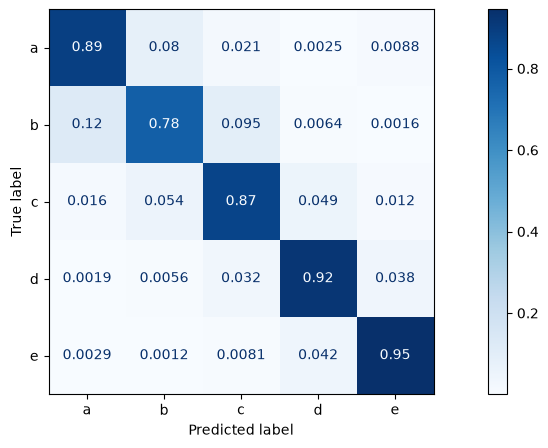

In [83]:

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(random_state=SEED, **study.best_params))
])

n_classes = len(grades)
encoded_labels = list(range(n_classes))

pipeline.fit(X_train, y_train_encoded)
y_pred_encoded = pipeline.predict(X_test)
cm = confusion_matrix(y_test_encoded, y_pred_encoded, labels=encoded_labels, normalize="true")

fig, axes = plt.subplots(1,1, figsize=(14,5))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=grades)
display.plot(ax=axes, cmap="Blues")
plt.show()

> Confusions (a>b) et (c>b)